5 candidate gauges


<Axes: >

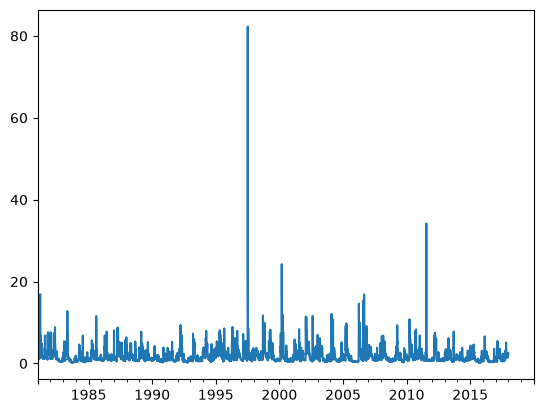

In [1]:
from rain2loss.lamah import CZECH_REGIONS, load_attributes, load_lamah

attrs = load_attributes()
candidates = attrs[attrs["fedstate"].isin(CZECH_REGIONS)
                   & attrs["degimpact"].isin(["u", "l"])]
print(len(candidates), "candidate gauges")

df = load_lamah(candidates.index[0], attrs)
df["qobs_mm"].plot()

In [2]:
import pandas as pd
from rain2loss.paths import LAMAH
from rain2loss.lamah import CZECH_REGIONS, load_attributes, load_lamah, read_lamah_ts

for folder in ["A_basins_total_upstrm/1_attributes", "D_gauges/1_attributes"]:
    print(folder, [f.name for f in (LAMAH / folder).glob("*.csv")])

A_basins_total_upstrm/1_attributes ['Catchment_attributes.csv', 'Stream_dist.csv', 'Water_balance.csv']
D_gauges/1_attributes ['Gauge_attributes.csv', 'Hydro_indices_1981_2017.csv', 'Hydro_indices_1989_2009.csv']


In [3]:
attrs = load_attributes()
print(attrs.shape)               # about 859 rows expected
print(attrs.columns.tolist())

(882, 84)
['area_calc', 'elev_mean', 'elev_med', 'elev_std', 'elev_ran', 'slope_mean', 'mvert_dist', 'mvert_ang', 'elon_ratio', 'strm_dens', 'p_mean', 'et0_mean', 'eta_mean', 'arid_1', 'arid_2', 'p_season', 'frac_snow', 'hi_prec_fr', 'hi_prec_du', 'hi_prec_ti', 'lo_prec_fr', 'lo_prec_du', 'lo_prec_ti', 'lc_dom', 'agr_fra', 'bare_fra', 'forest_fra', 'glac_fra', 'lake_fra', 'urban_fra', 'lai_max', 'lai_diff', 'ndvi_max', 'ndvi_min', 'gvf_max', 'gvf_diff', 'bedrk_dep', 'root_dep', 'soil_poros', 'soil_condu', 'soil_tawc', 'sand_fra', 'silt_fra', 'clay_fra', 'grav_fra', 'oc_fra', 'gc_dom', 'gc_ig_fra', 'gc_mt_fra', 'gc_pa_fra', 'gc_pb_fra', 'gc_pi_fra', 'gc_py_fra', 'gc_sc_fra', 'gc_sm_fra', 'gc_ss_fra', 'gc_su_fra', 'gc_va_fra', 'gc_vb_fra', 'gc_wb_fra', 'geol_perme', 'geol_poros', 'govnr', 'name', 'river', 'area_gov', 'elev', 'lon', 'lat', 'country', 'fedstate', 'region', 'obsbeg_day', 'obsbeg_hr', 'obsend', 'gaps_pre', 'gaps_post', 'area_ratio', 'nrs_euhyd', 'nrs_rivat', 'typimpact', 'di

In [4]:
candidates = attrs[attrs["fedstate"].isin(CZECH_REGIONS)
                   & attrs["degimpact"].isin(["u", "l"])]
candidates[["fedstate", "degimpact", "area_gov", "elev_mean"]].sort_values("area_gov")

,fedstate,degimpact,area_gov,elev_mean
ID,,,,
839,SMO,l,30.9,511.0
823,OLM,l,90.3,799.0
822,OLM,l,96.6,794.0
876,VYS,l,166.5,559.0
824,OLM,l,349.8,752.0


In [5]:
missing = {}
for gid in candidates.index:
    q = read_lamah_ts(LAMAH / f"D_gauges/2_timeseries/daily/ID_{gid}.csv")["qobs"]
    missing[gid] = (q < 0).mean()    # share of -999 days

candidates = candidates.assign(missing=pd.Series(missing))
candidates.sort_values("missing").head(10)

,area_calc,elev_mean,elev_med,elev_std,elev_ran,slope_mean,mvert_dist,mvert_ang,elon_ratio,strm_dens,...,gaps_pre,gaps_post,area_ratio,nrs_euhyd,nrs_rivat,typimpact,diur_art,diur_glac,degimpact,missing
ID,,,,,,,,,,,,,,,,,,,,,
822,96.823,794.0,744.0,207.0,990.0,149.0,13.8,159.0,0.805,0.79,...,0.0,0.0,1.002,RL35133225,20371554.0,-,0,0,l,0.0
823,91.114,799.0,762.0,193.0,970.0,148.0,15.4,189.0,0.699,0.73,...,0.0,0.0,1.009,RL35133239,20371809.0,-,0,0,l,0.0
824,351.002,752.0,703.0,198.0,1058.0,145.0,23.3,186.0,0.907,0.68,...,0.0,0.0,1.003,RL35133184,20373916.0,-,0,0,l,0.0
839,30.796,511.0,523.0,47.0,270.0,81.0,8.9,137.0,0.707,0.43,...,0.0,0.0,0.997,RL35131190,NaN,-,0,0,l,0.0
876,167.176,559.0,553.0,47.0,275.0,62.0,17.5,137.0,0.836,0.35,...,0.0,0.0,1.004,RL35131046,20389785.0,-,0,0,l,0.0


['DOY', '2m_temp_max', '2m_temp_mean', '2m_temp_min', '2m_dp_temp_max', '2m_dp_temp_mean', '2m_dp_temp_min', '10m_wind_u', '10m_wind_v', 'fcst_alb', 'lai_high_veg', 'lai_low_veg', 'swe', 'surf_net_solar_rad_max', 'surf_net_solar_rad_mean', 'surf_net_therm_rad_max', 'surf_net_therm_rad_mean', 'surf_press', 'total_et', 'prec', 'volsw_123', 'volsw_4', 'qobs_m3s', 'qobs_mm']


1997-12-31    82.285714
2011-12-31    34.187031
2000-12-31    24.238509
1981-12-31    16.904348
2006-12-31    16.843528
Name: qobs_mm, dtype: float64

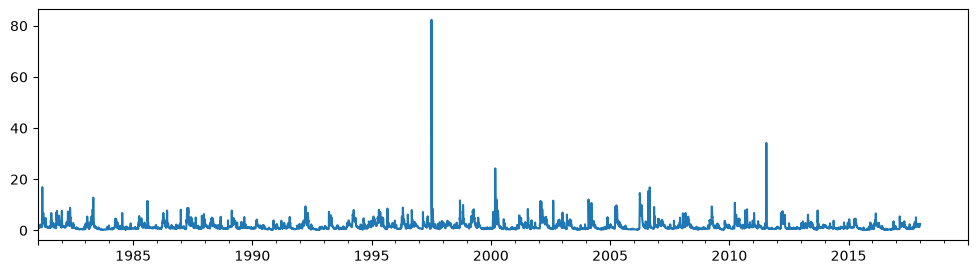

In [6]:
gid = candidates.sort_values("missing").index[0]   # or pick an ID by hand
df = load_lamah(gid, attrs)
print(df.columns.tolist())                         # find precipitation & temperature columns
df["qobs_mm"].plot(figsize=(12, 3))
df["qobs_mm"].resample("YE").max().nlargest(5)     # biggest years: is 1997 or 2002 among them?

In [7]:
for gid in candidates.index:
    d = load_lamah(gid, attrs)
    top = d["qobs_mm"].resample("YE").max().nlargest(3)
    print(gid, attrs.loc[gid, "area_gov"], [t.year for t in top.index])

attrs.loc[candidates.index].filter(regex="name|river")

822 96.6 [1997, 2011, 2000]
823 90.3 [1997, 1981, 2000]
824 349.8 [1997, 2011, 2000]
839 30.9 [2006, 2005, 2014]
876 166.5 [2006, 2005, 1985]


,name,river
ID,,
822,Vlaske,Morava
823,Jindrichov,Branna
824,Raskov,Morava
839,Opatovice nad nadrzi,Mala Hana
876,Baliny,Balinka
